# Vision-Based Gesture-to-Speech Translation for Sign Language

Python version: 3.12.6
Downloading dependencies.

In [1]:
%load_ext autoreload
%autoreload 2

%pip install torch torchvision kagglehub opencv-python

# pytorch
import torch

# kaggle (for downloading datasets) and dataset manage
import kagglehub as kh
import os

Note: you may need to restart the kernel to use updated packages.


In [2]:
# dataset download
lis_path = kh.dataset_download("nicholasnisopoli/lisdataset")
asl_path = kh.dataset_download("grassknoted/asl-alphabet")
print("Italian Sing Language dataset path:", lis_path)
print("American Sign Language dataset path:", asl_path)
lis_dataset = os.path.join(lis_path, "LIS-fingerspelling-dataset")
asl_dataset = os.path.join(asl_path, "asl_alphabet_train/asl_alphabet_train")

Italian Sing Language dataset path: /Users/anna/.cache/kagglehub/datasets/nicholasnisopoli/lisdataset/versions/1
American Sign Language dataset path: /Users/anna/.cache/kagglehub/datasets/grassknoted/asl-alphabet/versions/1


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## LIS model

In [ ]:
from code.train import train_and_save
from code.plotter import plot_loss, plot_acc

THRESH = 0.85
EPOCHS = 1 # 25
BATCH_SIZE = 32
LEARNING_RATE = 0.01

In [ ]:
lis_history = train_and_save(lis_dataset, THRESH, BATCH_SIZE, LEARNING_RATE, EPOCHS, device, "lis_model.pth")


Epoch 01/1 | train_loss=3.0894, train_acc=0.0512 | test_loss=3.0862, test_acc=0.0594
Model saved at models/lis_model.pth


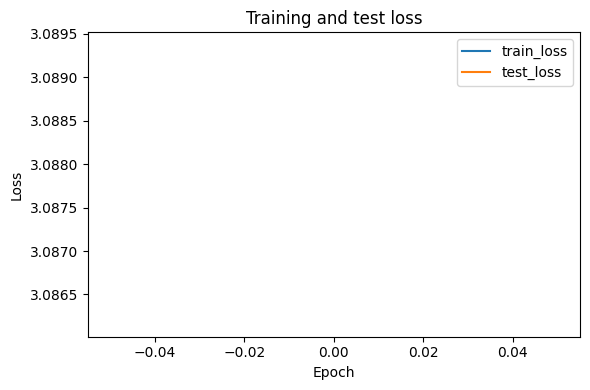

In [ ]:
plot_loss(lis_history)
plot_acc(lis_history)

## ASL model

In [ ]:
asl_history = train_and_save(asl_dataset, THRESH, BATCH_SIZE, LEARNING_RATE, EPOCHS, device, "lis_model.pth")
plot_loss(asl_history)
plot_acc(asl_history)